In [1]:
import os, gc, time, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import rasterio.transform
from rasterio.warp import transform as warp_transform
from scipy import ndimage
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_ROOT       = Path("/home/23CSU413/Deep Learning/AgriFieldNet")
SOURCE_DIR      = DATA_ROOT / "source"
TRAIN_LABEL_DIR = DATA_ROOT / "train_labels" / "train_labels"
TEST_LABEL_DIR  = DATA_ROOT / "test_labels"
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)

BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B11","B12"]
CROP_MAP = {1:"Wheat",2:"Mustard",3:"Lentil",4:"Fallow",5:"GreenPea",6:"Sugarcane",
            8:"Garlic",9:"Maize",13:"Gram",14:"Coriander",15:"Potato",16:"Berseem",36:"Rice"}
ORIG_LABELS = sorted(CROP_MAP)
LABEL2IDX   = {c: i for i, c in enumerate(ORIG_LABELS)}
CLASS_NAMES = [CROP_MAP[c] for c in ORIG_LABELS]
K = len(ORIG_LABELS)          # 13 classes
PATCH = 32                    # CNN patch size
USE_LOCATION = True           # use field lon/lat as features (set False to test without)

def chip_ids_from(folder):
    return sorted({p.stem.split("_")[-3] for p in folder.glob("*_field_ids.tif")})

all_chip_ids   = sorted(p.name.split("_")[-1] for p in SOURCE_DIR.iterdir() if p.is_dir())
train_chip_ids = chip_ids_from(TRAIN_LABEL_DIR)
test_chip_ids  = chip_ids_from(TEST_LABEL_DIR)
print("source chips:", len(all_chip_ids), "| train-label chips:", len(train_chip_ids),
      "| test-label chips:", len(test_chip_ids))

source chips: 1217 | train-label chips: 1165 | test-label chips: 707


In [2]:
rows = []
for cid in random.sample(all_chip_ids, 30):
    folder = SOURCE_DIR / f"ref_agrifieldnet_competition_v1_source_{cid}"
    for b in BANDS:
        with rasterio.open(folder / f"ref_agrifieldnet_competition_v1_source_{cid}_{b}_10m.tif") as src:
            a = src.read(1)
            rows.append(dict(band=b, dtype=str(a.dtype), nodata=src.nodata, min=float(a.min()),
                             max=float(a.max()), mean=float(a.mean()), zero_frac=float((a == 0).mean())))
chk = pd.DataFrame(rows)
print(chk.groupby("band", sort=False).agg(dtype=("dtype","first"), nodata=("nodata","first"),
      min=("min","min"), max=("max","max"), mean=("mean","mean"), zero_frac=("zero_frac","mean")).round(3))

folder0 = SOURCE_DIR / f"ref_agrifieldnet_competition_v1_source_{all_chip_ids[0]}"
print("\nFiles in one chip folder:", [p.name for p in folder0.iterdir()][:15])
for j in folder0.glob("*.json"):
    d = json.load(open(j))
    print(j.name, "-> datetime:", d.get("properties", {}).get("datetime"),
          "| start:", d.get("properties", {}).get("start_datetime"))

      dtype  nodata   min    max    mean  zero_frac
band                                               
B01   uint8     0.0  30.0   57.0  43.251        0.0
B02   uint8     0.0  23.0   61.0  38.528        0.0
B03   uint8     0.0  18.0   62.0  37.295        0.0
B04   uint8     0.0  15.0   74.0  38.527        0.0
B05   uint8     0.0  19.0   74.0  42.094        0.0
B06   uint8     0.0  22.0   81.0  55.101        0.0
B07   uint8     0.0  25.0  105.0  63.586        0.0
B08   uint8     0.0  22.0  104.0  60.437        0.0
B8A   uint8     0.0  22.0  115.0  70.229        0.0
B09   uint8     0.0   4.0   25.0  13.481        0.0
B11   uint8     0.0  11.0  112.0  68.741        0.0
B12   uint8     0.0   6.0  118.0  47.405        0.0

Files in one chip folder: ['ref_agrifieldnet_competition_v1_source_001c1_B06_10m.tif', 'ref_agrifieldnet_competition_v1_source_001c1_B03_10m.tif', 'ref_agrifieldnet_competition_v1_source_001c1_B08_10m.tif', 'ref_agrifieldnet_competition_v1_source_001c1_B09_10m.tif', 'ref

In [3]:
P, HALF = PATCH, PATCH // 2

def read_tif(p):
    with rasterio.open(p) as src:
        return src.read(1)

def extract_chip(cid):
    folder = SOURCE_DIR / f"ref_agrifieldnet_competition_v1_source_{cid}"
    bands = []
    for b in BANDS:
        with rasterio.open(folder / f"ref_agrifieldnet_competition_v1_source_{cid}_{b}_10m.tif") as src:
            bands.append(src.read(1).astype(np.float32))
            if b == "B02":
                tfm, crs = src.transform, src.crs.to_string()
    stack  = np.stack(bands)                                        # (12,H,W)
    padded = np.pad(stack, ((0,0),(HALF,HALF),(HALF,HALF)))

    jobs = []
    f_tr = TRAIN_LABEL_DIR / f"ref_agrifieldnet_competition_v1_labels_train_{cid}_field_ids.tif"
    c_tr = TRAIN_LABEL_DIR / f"ref_agrifieldnet_competition_v1_labels_train_{cid}.tif"
    f_te = TEST_LABEL_DIR  / f"ref_agrifieldnet_competition_v1_labels_test_{cid}_field_ids.tif"
    if f_tr.exists() and c_tr.exists(): jobs.append(("train", read_tif(f_tr), read_tif(c_tr)))
    if f_te.exists():                   jobs.append(("test",  read_tif(f_te), None))

    pix, pat = [], []
    for split, field, crop in jobs:
        field  = field.astype(np.int64)
        pfield = np.pad(field, HALF)
        for fid in np.unique(field):
            if fid == 0: continue
            m = field == fid
            label = 0
            if split == "train":
                cv = crop[m]; cv = cv[cv > 0]
                if cv.size == 0: continue
                vals, cnts = np.unique(cv, return_counts=True)
                orig = int(vals[cnts.argmax()])
                if orig not in LABEL2IDX: continue
                label = LABEL2IDX[orig]
            er = ndimage.binary_erosion(m, border_value=1)          # inner "core" pixels (no edge mixing)
            if er.sum() < 3: er = m                                 # tiny field: keep everything
            rr, cc = np.nonzero(m)
            xs, ys = rasterio.transform.xy(tfm, rr, cc)
            pix.append(dict(chip_id=cid, field_id=int(fid), split=split, label=label, n=rr.size,
                            core=er[rr, cc], X=stack[:, rr, cc].T,
                            x=float(np.mean(xs)), y=float(np.mean(ys)), crs=crs))
            r0, c0 = int(rr.mean()), int(cc.mean())
            pat.append(dict(field_id=int(fid), chip_id=cid, split=split, n=rr.size, label=label,
                            patch=padded[:, r0:r0+P, c0:c0+P].copy(),
                            mask=(pfield[r0:r0+P, c0:c0+P] == fid)))
    return pix, pat

def safe_extract(cid):
    try: return extract_chip(cid)
    except Exception as e:
        print(f"[skip] {cid}: {e}"); return [], []

need = ["pixels.pkl", "patches.npy", "masks.npy", "patch_meta.pkl"]
if all((CACHE / f).exists() for f in need):
    pix       = pd.read_pickle(CACHE / "pixels.pkl")
    patches   = np.load(CACHE / "patches.npy")
    masks     = np.load(CACHE / "masks.npy")
    pat_meta  = pd.read_pickle(CACHE / "patch_meta.pkl")
    print("Loaded from cache")
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(tqdm(ex.map(safe_extract, all_chip_ids), total=len(all_chip_ids)))
    pix_list = [d for r in results for d in r[0]]
    pat_list = [d for r in results for d in r[1]]
    del results

    # field-centroid lon/lat (done outside threads, grouped by CRS)
    lon = np.zeros(len(pix_list)); lat = np.zeros(len(pix_list))
    crs_arr = np.array([d["crs"] for d in pix_list])
    for c in np.unique(crs_arr):
        idx = np.where(crs_arr == c)[0]
        lo, la = warp_transform(c, "EPSG:4326", [pix_list[i]["x"] for i in idx], [pix_list[i]["y"] for i in idx])
        lon[idx], lat[idx] = lo, la

    ns  = np.array([d["n"] for d in pix_list])
    rep = lambda key: np.repeat([d[key] for d in pix_list], ns)
    pix = pd.DataFrame({
        "chip_id": rep("chip_id"), "field_id": rep("field_id").astype(np.int64),
        "split": rep("split"), "label": rep("label").astype(np.int16),
        "lon": np.repeat(lon, ns), "lat": np.repeat(lat, ns),
        "core": np.concatenate([d["core"] for d in pix_list])})
    Xall = np.concatenate([d["X"] for d in pix_list])
    for i, b in enumerate(BANDS): pix[b] = Xall[:, i]
    del Xall, pix_list

    # one patch per (split, field): keep the chip where the field is largest
    pat_meta = pd.DataFrame({k: [d[k] for d in pat_list] for k in ["field_id","chip_id","split","n","label"]})
    keep = np.sort(pat_meta.sort_values("n", ascending=False).drop_duplicates(["split","field_id"]).index.values)
    patches  = np.stack([pat_list[i]["patch"] for i in keep]).astype(np.float32)
    masks    = np.stack([pat_list[i]["mask"]  for i in keep])
    pat_meta = pat_meta.loc[keep].reset_index(drop=True)
    del pat_list; gc.collect()

    pix.to_pickle(CACHE / "pixels.pkl"); np.save(CACHE / "patches.npy", patches)
    np.save(CACHE / "masks.npy", masks); pat_meta.to_pickle(CACHE / "patch_meta.pkl")
    print("Saved cache")

print("pixel rows:", pix.shape, "| patches:", patches.shape)
print(pix.groupby("split").field_id.nunique().rename("n_fields"))
print("labels per field (should all be 1):", pix[pix.split=="train"].groupby("field_id").label.nunique().max())

Loaded from cache
pixel rows: (237546, 19) | patches: (7081, 12, 32, 32)
split
test     1530
train    5551
Name: n_fields, dtype: int64
labels per field (should all be 1): 1


In [4]:
def nd(a, b): return (a - b) / (a + b + 1e-6)

def add_indices(df):
    df["NDVI"]  = nd(df["B08"], df["B04"])
    df["GNDVI"] = nd(df["B08"], df["B03"])
    df["NDWI"]  = nd(df["B03"], df["B08"])
    df["NDMI"]  = nd(df["B08"], df["B11"])
    df["NBR"]   = nd(df["B08"], df["B12"])
    df["NDRE"]  = nd(df["B08"], df["B05"])
    df["NDRE2"] = nd(df["B8A"], df["B06"])
    df["CIre"]  = df["B07"] / (df["B05"] + 1e-6) - 1
    df["MSI"]   = df["B11"] / (df["B08"] + 1e-6)
    df["BSI"]   = nd(df["B11"] + df["B04"], df["B08"] + df["B02"])
    return df

IDX_NAMES  = ["NDVI","GNDVI","NDWI","NDMI","NBR","NDRE","NDRE2","CIre","MSI","BSI"]
BASE_FEATS = BANDS + IDX_NAMES
pix = add_indices(pix)
pix[BASE_FEATS] = pix[BASE_FEATS].replace([np.inf, -np.inf], np.nan).fillna(0).astype(np.float32)

# ---------- field-level table (statistics over inner/core pixels) ----------
key  = ["split", "field_id"]
core = pix[pix["core"]]
g    = core.groupby(key)[BASE_FEATS]
parts = [g.mean().add_suffix("_mean"), g.std().fillna(0).add_suffix("_std"),
         g.quantile(0.10).add_suffix("_p10"), g.quantile(0.50).add_suffix("_p50"),
         g.quantile(0.90).add_suffix("_p90")]
geo = pix.groupby(key).agg(area=("B08","size"), n_core=("core","sum"),
                           lon=("lon","mean"), lat=("lat","mean"),
                           label=("label","max"), n_chips=("chip_id","nunique"))
fields = geo.join(parts, how="left").reset_index()
fields["log_area"]   = np.log1p(fields["area"])
fields["edge_ratio"] = 1 - fields["n_core"] / fields["area"]

STAT_COLS   = [c for c in fields.columns if c.endswith(("_mean","_std","_p10","_p50","_p90"))]
LOC_COLS    = ["lon","lat"] if USE_LOCATION else []
FIELD_FEATS = STAT_COLS + ["log_area","edge_ratio"] + LOC_COLS
PIX_FEATS   = BASE_FEATS + ["log_area","edge_ratio"] + LOC_COLS
fields[FIELD_FEATS] = fields[FIELD_FEATS].replace([np.inf,-np.inf], np.nan).fillna(0)

ftr = fields[fields.split == "train"].reset_index(drop=True); ftr["label"] = ftr["label"].astype(int)
fte = fields[fields.split == "test"].reset_index(drop=True)

def link_pixels(split, ftab):
    p = pix[(pix.split == split) & pix["core"]].copy()
    mp = {fid: i for i, fid in enumerate(ftab.field_id)}
    p["fidx"] = p.field_id.map(mp).values
    for c in ["log_area","edge_ratio","lon","lat"]:
        p[c] = ftab[c].values[p["fidx"].values]
    return p.reset_index(drop=True)

pix_tr = link_pixels("train", ftr)
pix_te = link_pixels("test", fte)

print("train fields:", len(ftr), "| test fields:", len(fte))
print("field features:", len(FIELD_FEATS), "| pixel features:", len(PIX_FEATS))
print("train core pixels:", len(pix_tr), "| test core pixels:", len(pix_te))

train fields: 5551 | test fields: 1530
field features: 114 | pixel features: 26
train core pixels: 102193 | test core pixels: 26258


    class  fields  pixels  field_%
    Wheat    2031   75118    36.59
  Mustard     990   46818    17.83
   Lentil     103    2883     1.86
   Fallow    1641   36397    29.56
 GreenPea      23     531     0.41
Sugarcane     163    5820     2.94
   Garlic      48    3150     0.86
    Maize     293    8773     5.28
     Gram      59    3503     1.06
Coriander      14     678     0.25
   Potato      41     886     0.74
  Berseem      16     261     0.29
     Rice     129    3410     2.32
Majority-class baseline accuracy: 0.366


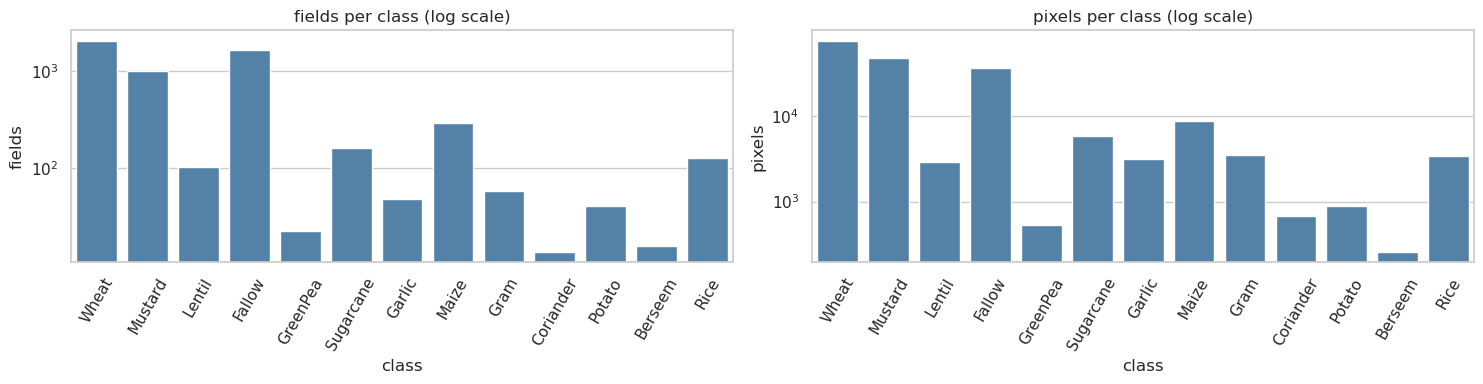

In [5]:
sns.set_theme(style="whitegrid")
pal = sns.color_palette("tab20", K)
cmap = dict(enumerate(CLASS_NAMES))

# 5.1 Class distribution (field + pixel level)
pix_cnt = pix[pix.split == "train"].label.value_counts().reindex(range(K), fill_value=0)
fld_cnt = ftr.label.value_counts().reindex(range(K), fill_value=0)
dist = pd.DataFrame({"class": CLASS_NAMES, "fields": fld_cnt.values, "pixels": pix_cnt.values})
dist["field_%"] = (100 * dist.fields / dist.fields.sum()).round(2)
print(dist.to_string(index=False))
print("Majority-class baseline accuracy:", round(dist.fields.max() / dist.fields.sum(), 3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, col in zip(ax, ["fields", "pixels"]):
    sns.barplot(x="class", y=col, data=dist, ax=a, color="steelblue")
    a.set_yscale("log"); a.set_title(f"{col} per class (log scale)"); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

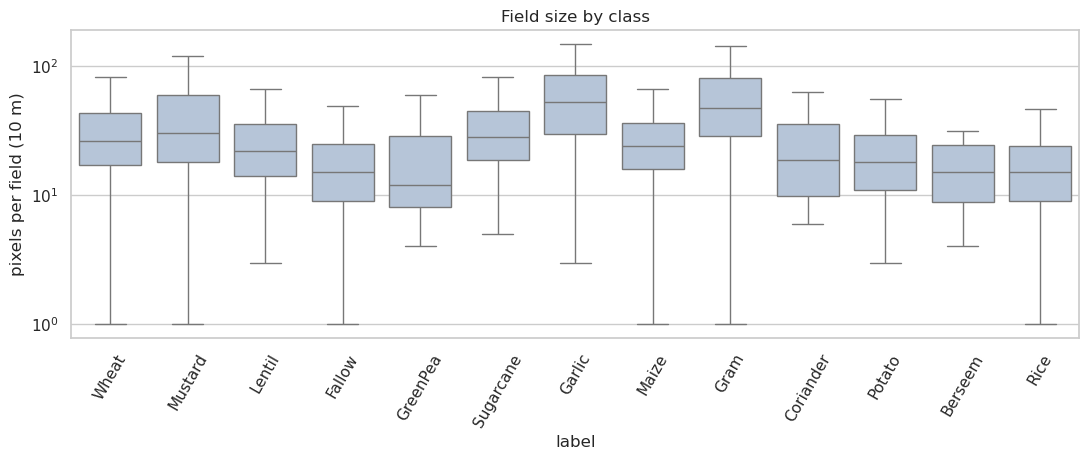

In [6]:
# 5.2 Field size per class
plt.figure(figsize=(13, 4))
sns.boxplot(x=ftr.label.map(cmap), y=ftr.area, order=CLASS_NAMES, showfliers=False, color="lightsteelblue")
plt.yscale("log"); plt.ylabel("pixels per field (10 m)"); plt.xticks(rotation=60)
plt.title("Field size by class"); plt.show()

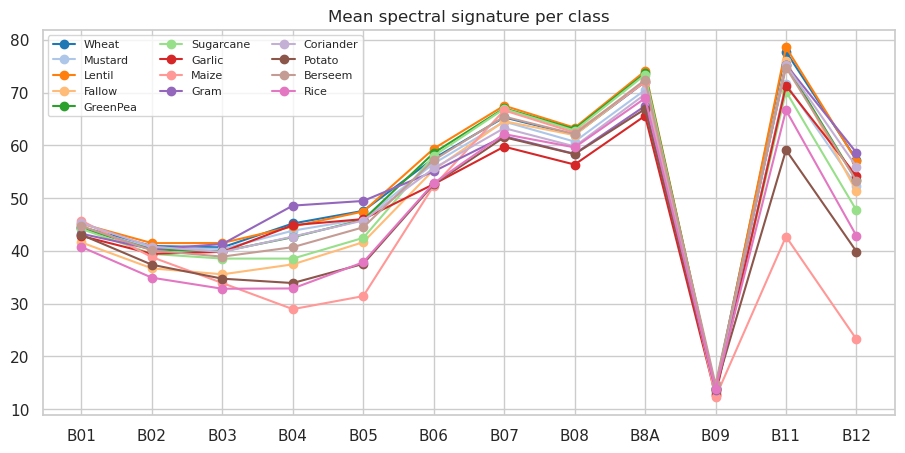

In [7]:
# 5.3 Mean spectral signature per class
sig = ftr.groupby("label")[[f"{b}_mean" for b in BANDS]].mean()
plt.figure(figsize=(11, 5))
for k in range(K): plt.plot(BANDS, sig.loc[k].values, marker="o", label=CLASS_NAMES[k], color=pal[k])
plt.legend(ncol=3, fontsize=8); plt.title("Mean spectral signature per class"); plt.show()

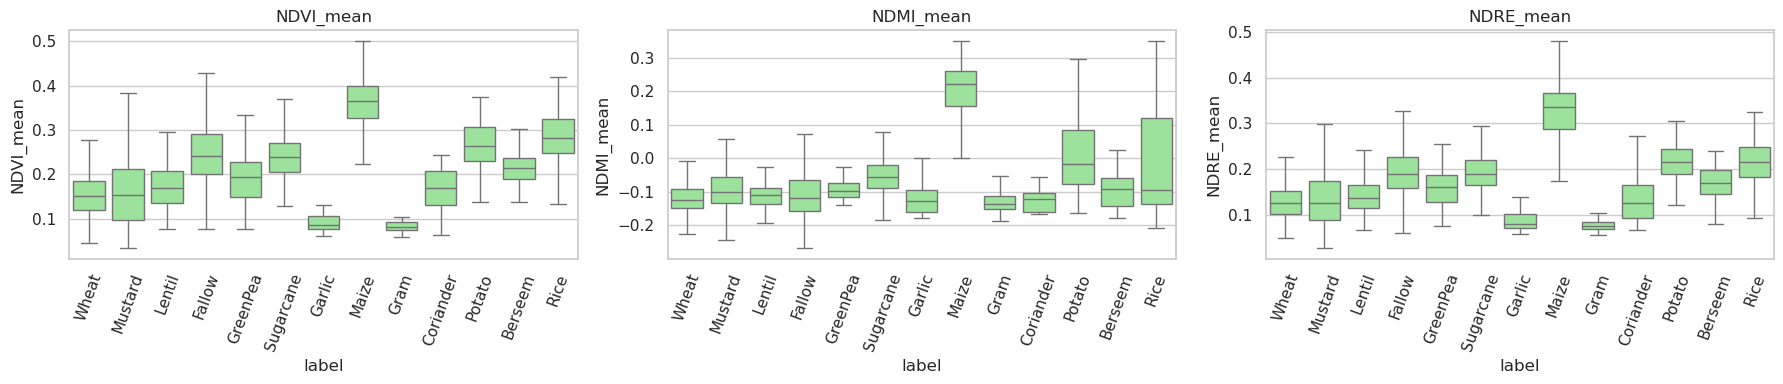

In [8]:
# 5.4 Index distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax_, c in zip(axes, ["NDVI_mean", "NDMI_mean", "NDRE_mean"]):
    sns.boxplot(x=ftr.label.map(cmap), y=ftr[c], order=CLASS_NAMES, showfliers=False, ax=ax_, color="lightgreen")
    ax_.tick_params(axis="x", rotation=70); ax_.set_title(c)
plt.tight_layout(); plt.show()

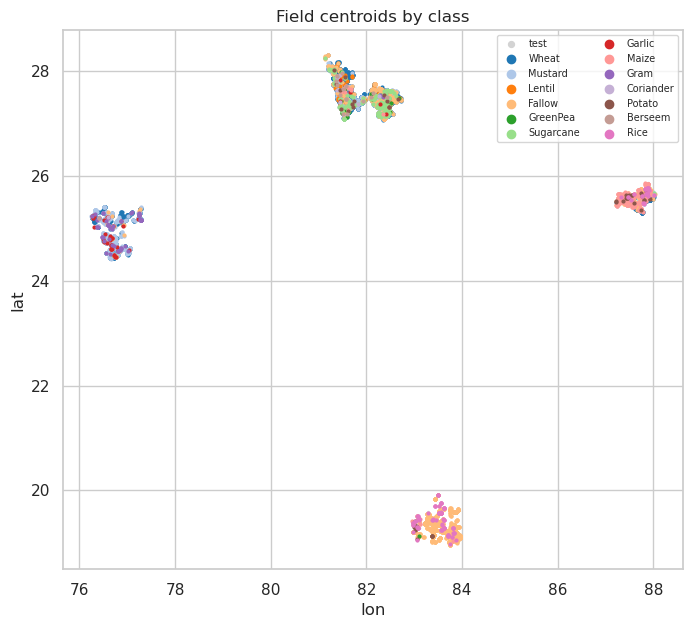

In [9]:
# 5.3b Geographic distribution (crop mix varies by region)
plt.figure(figsize=(8, 7))
plt.scatter(fte.lon, fte.lat, s=2, c="lightgrey", label="test")
for k in range(K):
    s = ftr[ftr.label == k]; plt.scatter(s.lon, s.lat, s=4, color=pal[k], label=CLASS_NAMES[k])
plt.legend(markerscale=3, fontsize=7, ncol=2); plt.xlabel("lon"); plt.ylabel("lat")
plt.title("Field centroids by class"); plt.show()

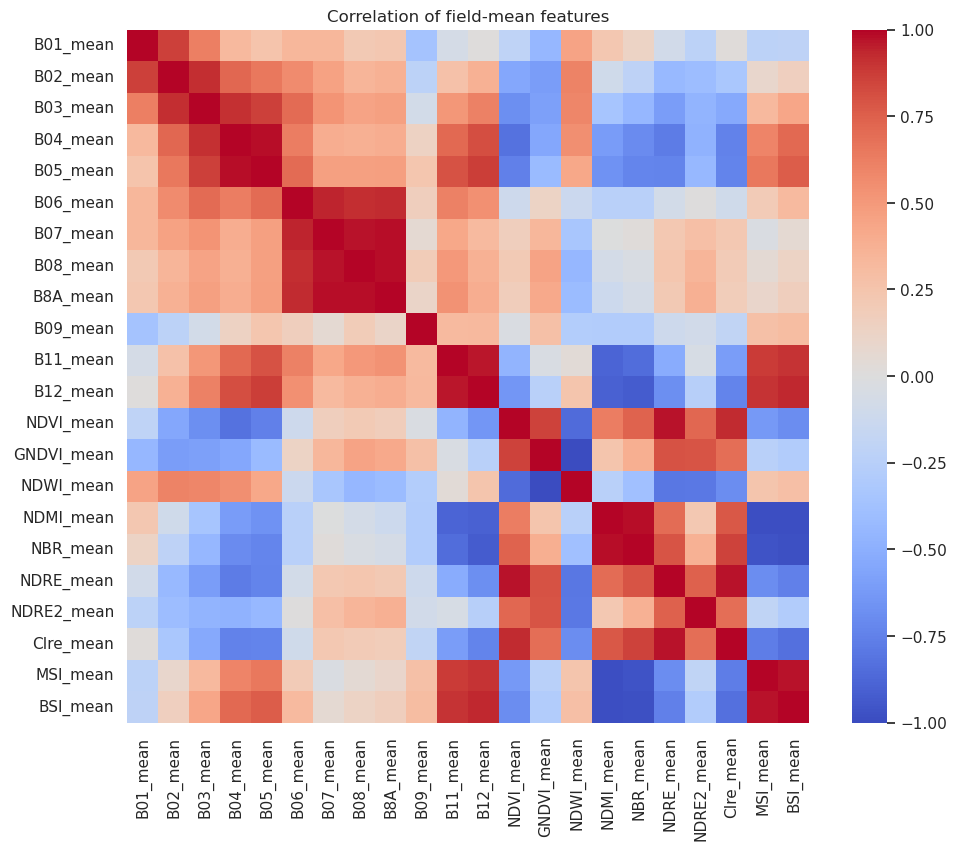

Chips per field:
 split      test   train
n_chips                
1        1458.0  5285.0
2          70.0   264.0
3           NaN     1.0
4           2.0     1.0


In [10]:
# 5.5 Correlation between mean features
plt.figure(figsize=(11, 9))
sns.heatmap(ftr[[f"{c}_mean" for c in BASE_FEATS]].corr(), cmap="coolwarm", center=0)
plt.title("Correlation of field-mean features"); plt.show()

# 5.6 Fields spanning several chips
print("Chips per field:\n", fields.groupby("split").n_chips.value_counts().unstack(0))

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

pairs = pix.loc[pix.split == "train", ["field_id", "chip_id"]].drop_duplicates()
parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

for fid, cid in zip(pairs.field_id.values, pairs.chip_id.values):
    union(f"f{fid}", f"c{cid}")
ftr["group"] = pd.factorize([find(f"f{fid}") for fid in ftr.field_id])[0]

gs = ftr.group.value_counts()
print("groups:", len(gs), "| largest group share of fields:", round(gs.iloc[0] / len(ftr), 3))

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
ftr["fold"] = -1
for k, (_, va) in enumerate(sgkf.split(ftr, ftr.label, ftr.group)):
    ftr.loc[va, "fold"] = k
print(pd.crosstab(ftr.label.map(cmap), ftr.fold))

y = ftr.label.values.astype(int); N = len(ftr)
FOLDS = [(np.where(ftr.fold != k)[0], np.where(ftr.fold == k)[0]) for k in range(5)]

groups: 958 | largest group share of fields: 0.015
fold         0    1    2    3    4
label                             
Berseem      4    0    5    4    3
Coriander    6    3    2    2    1
Fallow     367  439  258  282  295
Garlic      13   10   10   10    5
Gram        15   11   19    6    8
GreenPea     5    3    6    4    5
Lentil      25   27   10   22   19
Maize       58   53   42   69   71
Mustard    210  177  202  176  225
Potato      11    4   11    8    7
Rice        34   21   15   32   27
Sugarcane   42   36   33   16   36
Wheat      466  413  369  379  404


In [12]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

SUMMARY, OOF = {}, {}

def metrics(yt, yp):
    return dict(Accuracy=accuracy_score(yt, yp), BalancedAcc=balanced_accuracy_score(yt, yp),
                MacroF1=f1_score(yt, yp, average="macro"), WeightedF1=f1_score(yt, yp, average="weighted"))

def soft_weights(y_, power=0.5):
    """Square-root balanced class weights (gentler than full 'balanced')."""
    cnt = np.bincount(y_, minlength=K).astype(float); cnt[cnt == 0] = 1
    cw = (cnt.sum() / (K * cnt)) ** power
    return cw / cw[y_].mean()

def expand(p, classes):
    out = np.zeros((p.shape[0], K)); out[:, classes] = p; return out

def agg_proba(p, fidx, n):
    """Average pixel probabilities per field (field-level voting)."""
    out = np.zeros((n, K)); cnt = np.zeros(n)
    np.add.at(out, fidx, p); np.add.at(cnt, fidx, 1)
    return out / np.maximum(cnt, 1)[:, None]

def run_cv(name, fit_predict):
    oof = np.zeros((N, K)); t0 = time.time()
    for k, (tr, va) in enumerate(FOLDS):
        oof[va] = fit_predict(tr, va)
        m = metrics(y[va], oof[va].argmax(1))
        print(f"  fold {k}: acc={m['Accuracy']:.3f}  bal={m['BalancedAcc']:.3f}  macroF1={m['MacroF1']:.3f}")
    OOF[name] = oof; SUMMARY[name] = metrics(y, oof.argmax(1))
    print(f"{name}: " + "  ".join(f"{a}={b:.3f}" for a, b in SUMMARY[name].items()) + f"   ({time.time()-t0:.0f}s)\n")

Xf   = ftr[FIELD_FEATS].values.astype(np.float32)      # field-level features
Xpix = pix_tr[PIX_FEATS].values.astype(np.float32)     # pixel-level features
pf   = pix_tr.fidx.values                              # pixel -> field row
ypix = y[pf]
core_cnt = np.bincount(pf, minlength=N)

def pixel_weights(mask, cw):
    w = cw[ypix[mask]] / np.sqrt(core_cnt[pf[mask]])   # class weight x field-size balance
    return (w / w.mean()).astype(np.float32)

In [13]:
from sklearn.ensemble import RandomForestClassifier

def fp_rf_field(tr, va):
    cw = soft_weights(y[tr])
    m = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED,
                               class_weight={i: cw[i] for i in range(K)})
    m.fit(Xf[tr], y[tr])
    return expand(m.predict_proba(Xf[va]), m.classes_)

def fp_rf_pixel(tr, va):
    mt = np.isin(pf, tr); mv = np.isin(pf, va)
    cw = soft_weights(ypix[mt])
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                               max_samples=0.5, n_jobs=-1, random_state=SEED)
    m.fit(Xpix[mt], ypix[mt], sample_weight=pixel_weights(mt, cw))
    p = expand(m.predict_proba(Xpix[mv]), m.classes_)
    return agg_proba(p, pf[mv], N)[va]

print("== Random Forest (field features) =="); run_cv("RF (field)", fp_rf_field)
print("== Random Forest (pixels + field voting) =="); run_cv("RF (pixel+vote)", fp_rf_pixel)

== Random Forest (field features) ==
  fold 0: acc=0.646  bal=0.233  macroF1=0.236
  fold 1: acc=0.655  bal=0.234  macroF1=0.232
  fold 2: acc=0.615  bal=0.220  macroF1=0.220
  fold 3: acc=0.662  bal=0.242  macroF1=0.230
  fold 4: acc=0.615  bal=0.220  macroF1=0.212
RF (field): Accuracy=0.639  BalancedAcc=0.226  MacroF1=0.224  WeightedF1=0.603   (15s)

== Random Forest (pixels + field voting) ==
  fold 0: acc=0.662  bal=0.247  macroF1=0.250
  fold 1: acc=0.677  bal=0.261  macroF1=0.268
  fold 2: acc=0.626  bal=0.237  macroF1=0.235
  fold 3: acc=0.643  bal=0.243  macroF1=0.231
  fold 4: acc=0.618  bal=0.241  macroF1=0.237
RF (pixel+vote): Accuracy=0.647  BalancedAcc=0.241  MacroF1=0.240  WeightedF1=0.615   (24s)



In [14]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def fp_svm(tr, va):
    cw = soft_weights(y[tr])
    m = make_pipeline(StandardScaler(),
                      SVC(kernel="rbf", C=10, gamma="scale", probability=True,
                          class_weight={i: cw[i] for i in range(K)}, random_state=SEED))
    m.fit(Xf[tr], y[tr])
    return expand(m.predict_proba(Xf[va]), m.classes_)

print("== SVM (RBF, field features) =="); run_cv("SVM (field)", fp_svm)

== SVM (RBF, field features) ==
  fold 0: acc=0.650  bal=0.232  macroF1=0.232
  fold 1: acc=0.673  bal=0.231  macroF1=0.233
  fold 2: acc=0.621  bal=0.208  macroF1=0.208
  fold 3: acc=0.655  bal=0.228  macroF1=0.216
  fold 4: acc=0.623  bal=0.219  macroF1=0.214
SVM (field): Accuracy=0.645  BalancedAcc=0.222  MacroF1=0.219  WeightedF1=0.609   (26s)



In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
tf.keras.utils.set_random_seed(SEED)

def build_mlp(d):
    m = models.Sequential([
        layers.Input((d,)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64,  activation="relu"), layers.BatchNormalization(), layers.Dropout(0.2),
        layers.Dense(K, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    return m

def fp_ann(tr, va):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    rng = np.random.RandomState(SEED)
    inner = rng.choice(tr, size=int(0.1 * len(tr)), replace=False)       # inner val for early stopping
    fit_f = np.setdiff1d(tr, inner)
    mt, mi, mv = np.isin(pf, fit_f), np.isin(pf, inner), np.isin(pf, va)
    cw = soft_weights(ypix[mt])
    sc = StandardScaler().fit(Xpix[mt])
    model = build_mlp(Xpix.shape[1])
    cb = [callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(factor=0.5, patience=3)]
    model.fit(sc.transform(Xpix[mt]), ypix[mt], sample_weight=pixel_weights(mt, cw),
              validation_data=(sc.transform(Xpix[mi]), ypix[mi], pixel_weights(mi, cw)),
              epochs=40, batch_size=512, callbacks=cb, verbose=0)
    p = model.predict(sc.transform(Xpix[mv]), batch_size=2048, verbose=0)
    return agg_proba(p, pf[mv], N)[va]

print("== ANN (pixel MLP + voting) =="); run_cv("ANN (pixel+vote)", fp_ann)

2026-10-18 17:32:18.390181: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 17:32:18.414802: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16, in other operations, rebuild TensorFlow with the appropriate compiler flags.


== ANN (pixel MLP + voting) ==
  fold 0: acc=0.631  bal=0.280  macroF1=0.257
  fold 1: acc=0.647  bal=0.371  macroF1=0.299
  fold 2: acc=0.609  bal=0.283  macroF1=0.270
  fold 3: acc=0.598  bal=0.306  macroF1=0.264
  fold 4: acc=0.588  bal=0.311  macroF1=0.272
ANN (pixel+vote): Accuracy=0.616  BalancedAcc=0.304  MacroF1=0.276  WeightedF1=0.617   (89s)



In [16]:
# ----- align patches with ftr and prepare inputs -----
idx_map = {(s, f): i for i, (s, f) in enumerate(zip(pat_meta.split, pat_meta.field_id))}
tr_pi = np.array([idx_map[("train", f)] for f in ftr.field_id])

def prep_img(arr):                                           # (n,12,P,P) -> (n,P,P,14)
    b = {n_: arr[:, i] for i, n_ in enumerate(BANDS)}
    ndvi = (b["B08"] - b["B04"]) / (b["B08"] + b["B04"] + 1e-6)
    ndmi = (b["B08"] - b["B11"]) / (b["B08"] + b["B11"] + 1e-6)
    out = np.concatenate([arr, ndvi[:, None], ndmi[:, None]], axis=1)
    return np.transpose(out, (0, 2, 3, 1)).astype(np.float32)

IMG = prep_img(patches[tr_pi])
MSK = masks[tr_pi][..., None].astype(np.float32)
flat = IMG.reshape(-1, IMG.shape[-1])[::7]; flat = flat[flat[:, :12].sum(1) > 0]
mu, sd = flat.mean(0), flat.std(0) + 1e-6
IMG = ((IMG - mu) / sd).astype(np.float32); del flat; gc.collect()

TAB_COLS = ["log_area", "edge_ratio"] + LOC_COLS
TAB = ftr[TAB_COLS].values.astype(np.float32); TAB = (TAB - TAB.mean(0)) / (TAB.std(0) + 1e-6)

class MaskedGAP(layers.Layer):
    """Average features inside the target field (masked) + overall context average."""
    def call(self, inputs):
        x, m = inputs
        masked = tf.reduce_sum(x * m, axis=[1, 2]) / (tf.reduce_sum(m, axis=[1, 2]) + 1e-6)
        plain  = tf.reduce_mean(x, axis=[1, 2])
        return tf.concat([masked, plain], axis=-1)
    def compute_output_shape(self, shapes):
        return (shapes[0][0], shapes[0][-1] * 2)

def build_cnn():
    img = layers.Input((P, P, IMG.shape[-1]), name="img")
    msk = layers.Input((P, P, 1), name="msk")
    tab = layers.Input((TAB.shape[1],), name="tab")
    x = layers.Concatenate()([img, msk])
    for f in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)                              # 32 -> 16 -> 8 -> 4
    m4 = layers.AveragePooling2D(8)(msk)                          # mask at 4x4
    feat = MaskedGAP()([x, m4])
    t = layers.Dense(16, activation="relu")(tab)
    h = layers.Concatenate()([feat, t])
    h = layers.Dense(128, activation="relu")(h); h = layers.BatchNormalization()(h); h = layers.Dropout(0.4)(h)
    out = layers.Dense(K, activation="softmax")(h)
    model = models.Model({"img": img, "msk": msk, "tab": tab}, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    return model

def aug(x, yy, ww):
    both = tf.concat([x["img"], x["msk"]], -1)
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    both = tf.image.rot90(both, tf.random.uniform((), 0, 4, dtype=tf.int32))
    both = tf.ensure_shape(both, [P, P, IMG.shape[-1] + 1])
    return {"img": both[..., :-1], "msk": both[..., -1:], "tab": x["tab"]}, yy, ww

def make_ds(ids, train, w):
    ds = tf.data.Dataset.from_tensor_slices(({"img": IMG[ids], "msk": MSK[ids], "tab": TAB[ids]}, y[ids], w))
    if train: ds = ds.shuffle(len(ids), seed=SEED).map(aug, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(64).prefetch(1)

def fp_cnn(tr, va):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    rng = np.random.RandomState(SEED)
    inner = rng.choice(tr, size=int(0.1 * len(tr)), replace=False)
    fit_f = np.setdiff1d(tr, inner)
    cw = soft_weights(y[fit_f])
    w_fit = (cw[y[fit_f]] / cw[y[fit_f]].mean()).astype(np.float32)
    w_in  = (cw[y[inner]] / cw[y[fit_f]].mean()).astype(np.float32)
    model = build_cnn()
    cb = [callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    model.fit(make_ds(fit_f, True, w_fit), validation_data=make_ds(inner, False, w_in),
              epochs=60, callbacks=cb, verbose=0)
    return model.predict({"img": IMG[va], "msk": MSK[va], "tab": TAB[va]}, batch_size=128, verbose=0)

print("== CNN (patch + mask channel) =="); run_cv("CNN (patch+mask)", fp_cnn)

== CNN (patch + mask channel) ==
  fold 0: acc=0.575  bal=0.282  macroF1=0.258
  fold 1: acc=0.614  bal=0.295  macroF1=0.238
  fold 2: acc=0.533  bal=0.327  macroF1=0.275
  fold 3: acc=0.559  bal=0.279  macroF1=0.238
  fold 4: acc=0.545  bal=0.264  macroF1=0.231
CNN (patch+mask): Accuracy=0.567  BalancedAcc=0.287  MacroF1=0.250  WeightedF1=0.575   (1327s)



In [17]:
ENS = ["RF (field)", "RF (pixel+vote)", "ANN (pixel+vote)", "CNN (patch+mask)"]
ENS = [n for n in ENS if n in OOF]
ens = np.mean([OOF[n] for n in ENS], axis=0)
SUMMARY["Ensemble (" + "+".join(ENS) + ")"] = metrics(y, ens.argmax(1)); OOF["Ensemble"] = ens

prior = np.bincount(y, minlength=K) / N
rows = []
for a in np.arange(0, 1.01, 0.1):
    pred = (ens / (prior ** a)).argmax(1)
    rows.append(dict(alpha=round(a, 1), **metrics(y, pred)))
tune = pd.DataFrame(rows); print(tune.round(3).to_string(index=False))

best_alpha = float(tune.loc[tune.MacroF1.idxmax(), "alpha"]); print("chosen alpha:", best_alpha)
ens_adj = ens / (prior ** best_alpha); ens_adj /= ens_adj.sum(1, keepdims=True)
SUMMARY[f"Ensemble + prior correction (a={best_alpha})"] = metrics(y, ens_adj.argmax(1)); OOF["Ensemble_adj"] = ens_adj

 alpha  Accuracy  BalancedAcc  MacroF1  WeightedF1
   0.0     0.648        0.257    0.245       0.620
   0.1     0.641        0.280    0.268       0.624
   0.2     0.617        0.302    0.274       0.616
   0.3     0.579        0.337    0.283       0.603
   0.4     0.526        0.371    0.280       0.574
   0.5     0.461        0.397    0.263       0.527
   0.6     0.387        0.402    0.242       0.463
   0.7     0.306        0.401    0.217       0.375
   0.8     0.235        0.387    0.191       0.285
   0.9     0.183        0.385    0.171       0.211
   1.0     0.148        0.365    0.157       0.161
chosen alpha: 0.3


,Accuracy,BalancedAcc,MacroF1,WeightedF1
Ensemble + prior correction (a=0.3),0.5790,0.3368,0.2834,0.6032
ANN (pixel+vote),0.6157,0.3040,0.2758,0.6174
CNN (patch+mask),0.5671,0.2866,0.2499,0.5746
Ensemble (RF (field)+RF (pixel+vote)+ANN (pixel+vote)+CNN (patch+mask)),0.6476,0.2573,0.2448,0.6203
RF (pixel+vote),0.6466,0.2411,0.2399,0.6146
RF (field),0.6392,0.2259,0.2236,0.6033
SVM (field),0.6455,0.2219,0.2190,0.6091


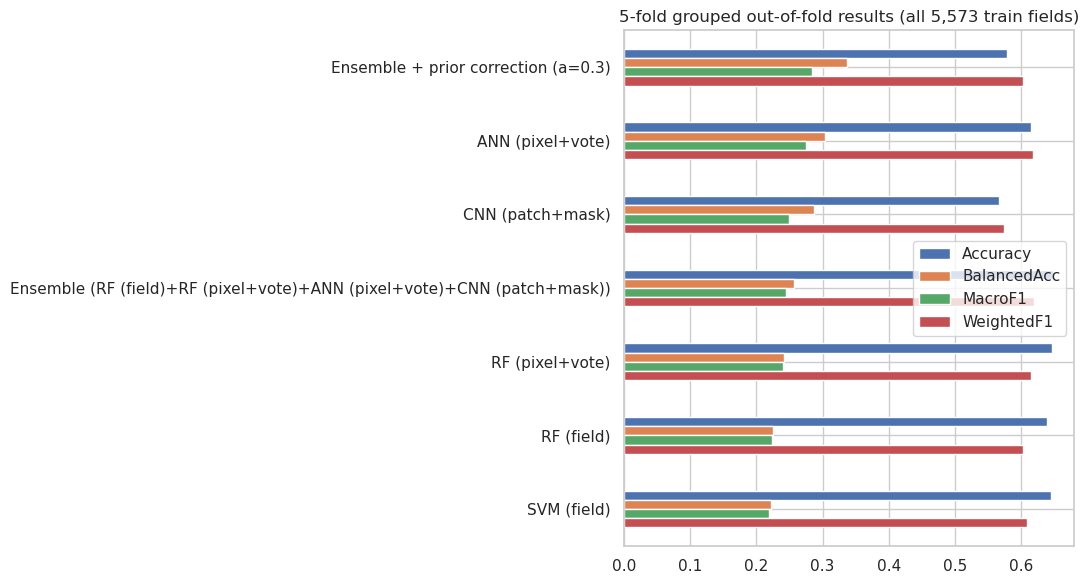

Best by macro-F1: Ensemble + prior correction (a=0.3)
              precision    recall  f1-score   support

       Wheat       0.71      0.69      0.70      2031
     Mustard       0.49      0.30      0.37       990
      Lentil       0.07      0.09      0.08       103
      Fallow       0.88      0.66      0.75      1641
    GreenPea       0.01      0.04      0.02        23
   Sugarcane       0.21      0.63      0.32       163
      Garlic       0.10      0.33      0.15        48
       Maize       0.59      0.86      0.70       293
        Gram       0.10      0.19      0.13        59
   Coriander       0.02      0.07      0.03        14
      Potato       0.07      0.17      0.10        41
     Berseem       0.00      0.00      0.00        16
        Rice       0.31      0.35      0.33       129

    accuracy                           0.58      5551
   macro avg       0.27      0.34      0.28      5551
weighted avg       0.66      0.58      0.60      5551



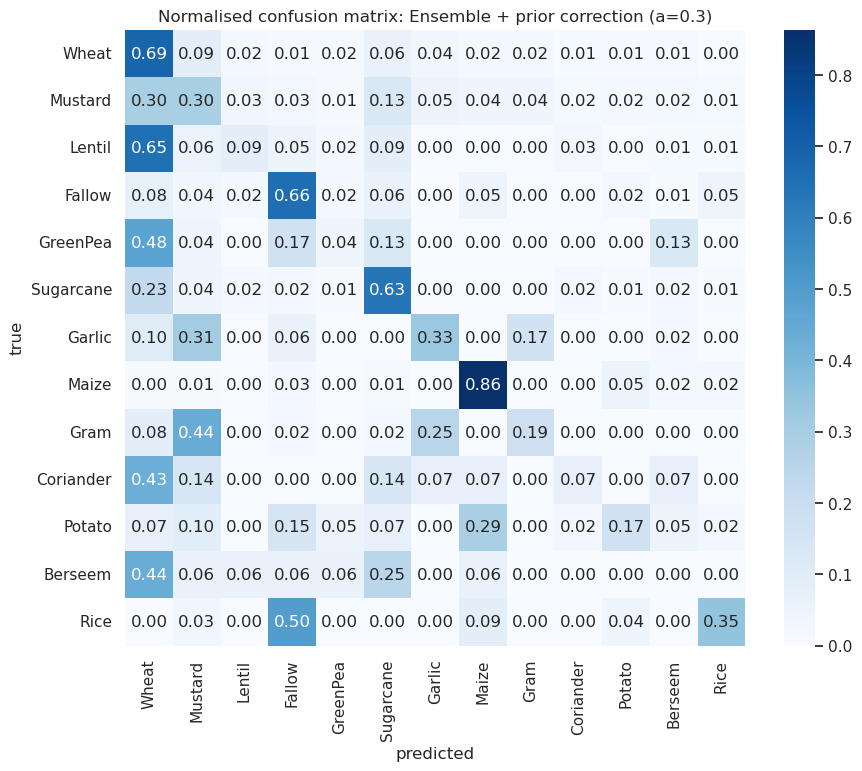

In [18]:
res = pd.DataFrame(SUMMARY).T.sort_values("MacroF1", ascending=False).round(4)
display(res)
res.to_csv("final_results_oof_5fold.csv")

ax = res[["Accuracy","BalancedAcc","MacroF1","WeightedF1"]].plot(kind="barh", figsize=(11, 6))
ax.invert_yaxis(); plt.title("5-fold grouped out-of-fold results (all 5,573 train fields)"); plt.tight_layout(); plt.show()

best = res.index[0]; print("Best by macro-F1:", best)
best_key = "Ensemble_adj" if best.startswith("Ensemble +") else ("Ensemble" if best.startswith("Ensemble") else best)
pred = OOF[best_key].argmax(1)
print(classification_report(y, pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y, pred, normalize="true")
plt.figure(figsize=(10, 8)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Normalised confusion matrix: {best}"); plt.show()

In [19]:
# Field-level RF
cw = soft_weights(y)
rf_f = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED,
                              class_weight={i: cw[i] for i in range(K)}).fit(Xf, y)
p_field = expand(rf_f.predict_proba(fte[FIELD_FEATS].values.astype(np.float32)), rf_f.classes_)

# Pixel-level RF + voting
allmask = np.ones(len(pf), bool)
cwp = soft_weights(ypix)
rf_p = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                              max_samples=0.5, n_jobs=-1, random_state=SEED)
rf_p.fit(Xpix, ypix, sample_weight=pixel_weights(allmask, cwp))
p_pix = expand(rf_p.predict_proba(pix_te[PIX_FEATS].values.astype(np.float32)), rf_p.classes_)
p_pixf = agg_proba(p_pix, pix_te.fidx.values, len(fte))

p_test = (p_field + p_pixf) / 2
sub = pd.DataFrame(p_test, columns=CLASS_NAMES); sub.insert(0, "field_id", fte.field_id.values)
sub.insert(1, "pred_crop", [CLASS_NAMES[i] for i in p_test.argmax(1)])
sub.to_csv("test_predictions_rf.csv", index=False)
print(sub.head()); print(sub.pred_crop.value_counts())

   field_id pred_crop     Wheat   Mustard    Lentil    Fallow  GreenPea  \
0        11     Wheat  0.358200  0.234559  0.012198  0.127016  0.022477   
1        13     Wheat  0.413823  0.244604  0.039874  0.227224  0.006926   
2        19     Wheat  0.490781  0.273689  0.072616  0.079336  0.003946   
3        21   Mustard  0.123678  0.342271  0.041048  0.261175  0.005380   
4        25    Fallow  0.144701  0.045303  0.027398  0.774661  0.001161   

   Sugarcane    Garlic     Maize      Gram  Coriander    Potato   Berseem  \
0   0.218964  0.004636  0.003894  0.000187   0.002971  0.010576  0.003257   
1   0.046322  0.001000  0.000000  0.001000   0.001538  0.000816  0.013921   
2   0.070336  0.002373  0.000091  0.001000   0.004192  0.001088  0.000553   
3   0.197202  0.005205  0.003095  0.001952   0.000000  0.016223  0.002771   
4   0.002392  0.000000  0.000098  0.000172   0.000115  0.000000  0.001000   

       Rice  
0  0.001065  
1  0.002952  
2  0.000000  
3  0.000000  
4  0.003000  
pr